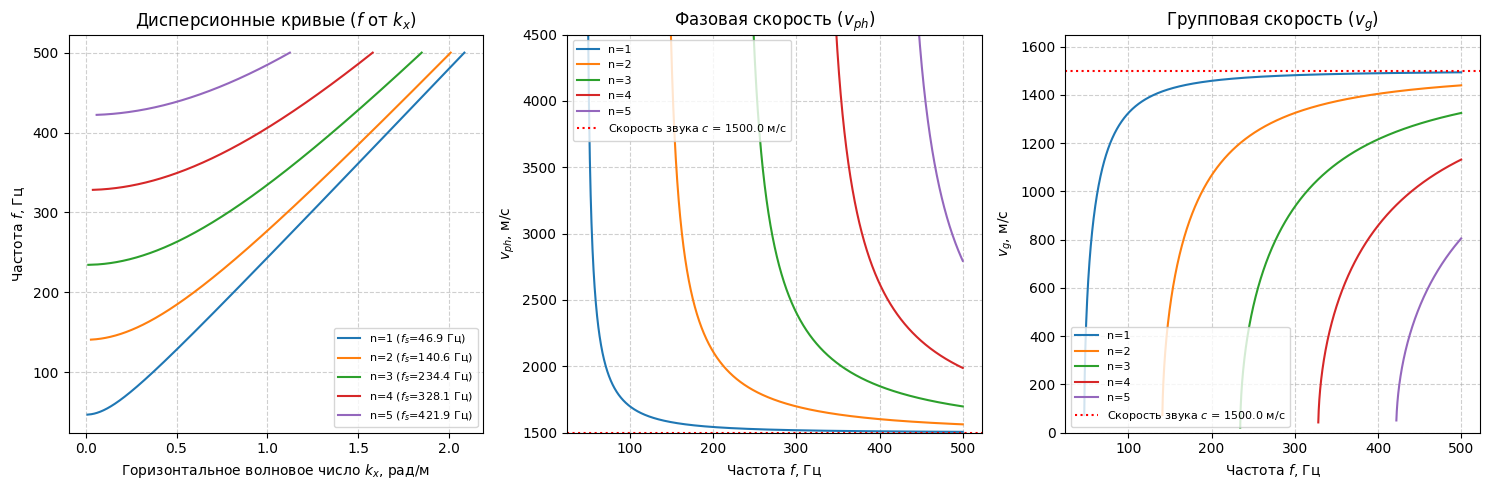

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. ПАРАМЕТРЫ СРЕДЫ И ВОЛНОВОДА
# ==========================================
H = 8.0          # Глубина водного слоя, м
c = 1500.0       # Скорость звука в воде, м/с
num_modes = 5    # Количество рассчитываемых мод (n = 1, 2, ..., 5)

# Частотная сетка для расчетов (от 1 Гц до 500 Гц)
f = np.linspace(1.0, 500.0, 2000)
omega = 2 * np.pi * f

plt.figure(figsize=(15, 5))

# ==========================================
# 2. ПОСТРОЕНИЕ ГРАФИКОВ
# ==========================================

# --- График 1: Частота от волнового числа f(k_x) ---
plt.subplot(1, 3, 1)
for n in range(1, num_modes + 1):
    # Частота среза для моды n
    f_n = c * (2 * n - 1) / (4 * H)
    
    # Вертикальное волновое число
    k_z_n = (2 * n - 1) * np.pi / (2 * H)
    
    # Полный волновой вектор
    k = omega / c
    
    # Горизонтальное волновое число k_x (активно только при f >= f_n)
    valid = k >= k_z_n
    if np.any(valid):
        k_x = np.sqrt(k[valid]**2 - k_z_n**2)
        plt.plot(k_x, f[valid], label=f'n={n} ($f_s$={f_n:.1f} Гц)')

plt.title('Дисперсионные кривые ($f$ от $k_x$)')
plt.xlabel('Горизонтальное волновое число $k_x$, рад/м')
plt.ylabel('Частота $f$, Гц')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=8)


# --- График 2: Фазовая скорость v_ph(f) ---
plt.subplot(1, 3, 2)
for n in range(1, num_modes + 1):
    f_n = c * (2 * n - 1) / (4 * H)
    valid = f > f_n
    if np.any(valid):
        f_sub = f[valid]
        omega_sub = 2 * np.pi * f_sub
        k_z_n = (2 * n - 1) * np.pi / (2 * H)
        k_x = np.sqrt((omega_sub / c)**2 - k_z_n**2)
        v_ph = omega_sub / k_x
        plt.plot(f_sub, v_ph, label=f'n={n}')

plt.axhline(y=c, color='r', linestyle=':', label=f'Скорость звука $c$ = {c} м/с')
plt.title('Фазовая скорость ($v_{ph}$)')
plt.xlabel('Частота $f$, Гц')
plt.ylabel('$v_{ph}$, м/с')
plt.ylim(c, c * 3) # Ограничим для наглядности (на срезе v_ph стремится к бесконечности)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=8)


# --- График 3: Групповая скорость v_g(f) ---
plt.subplot(1, 3, 3)
for n in range(1, num_modes + 1):
    f_n = c * (2 * n - 1) / (4 * H)
    valid = f > f_n
    if np.any(valid):
        f_sub = f[valid]
        # Аналитическая формула групповой скорости для жесткого дна
        v_g = c * np.sqrt(1.0 - (f_n / f_sub)**2)
        plt.plot(f_sub, v_g, label=f'n={n}')

plt.axhline(y=c, color='r', linestyle=':', label=f'Скорость звука $c$ = {c} м/с')
plt.title('Групповая скорость ($v_g$)')
plt.xlabel('Частота $f$, Гц')
plt.ylabel('$v_g$, м/с')
plt.ylim(0, c * 1.1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=8)

plt.tight_layout()
plt.show()

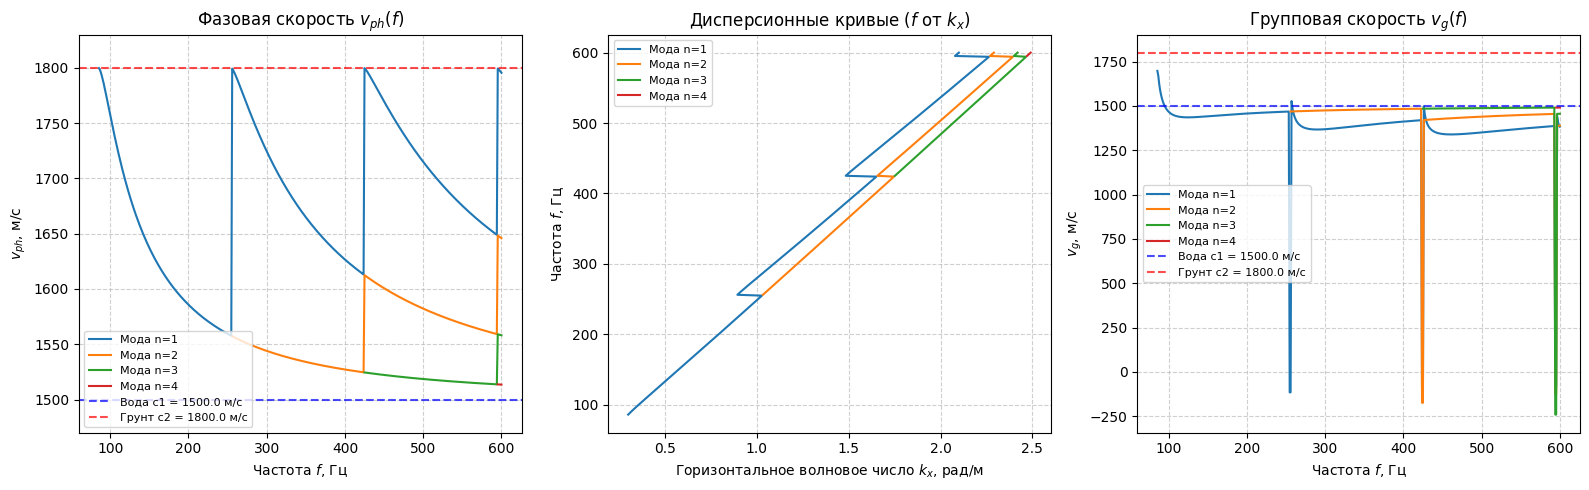

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ==========================================
# ПАРАМЕТРЫ ВОЛНОВОДА ПЕККЕРИСА
# ==========================================
H = 8.0          # Глубина водного слоя, м
c1 = 1500.0      # Скорость звука в воде, м/с
rho1 = 1000.0    # Плотность воды, кг/м^3
c2 = 1800.0      # Скорость звука в грунте, м/с (c2 > c1)
rho2 = 2000.0    # Плотность грунта, кг/м^3

# Частотная сетка (от 10 Гц до 600 Гц)
f_grid = np.linspace(10.0, 600.0, 500)
# Сетка фазовых скоростей в интервале (c1, c2)
v_grid = np.linspace(c1 + 0.1, c2 - 0.1, 4000)

# ==========================================
# ТОЧНОЕ ДИСПЕРСИОННОЕ УРАВНЕНИЕ ПЕККЕРИСА
# ==========================================
def pekeris_disp_eq(v_ph, f):
    omega = 2 * np.pi * f
    k1 = omega / c1
    val_z1 = 1.0 - (c1 / v_ph)**2
    val_z2 = (c1 / v_ph)**2 - (c1 / c2)**2
    
    if val_z1 < 0 or val_z2 < 0:
        return 0.0
    
    k_z1 = k1 * np.sqrt(val_z1)
    k_z2 = k1 * np.sqrt(val_z2)
    
    # Непрерывное уравнение Пеккериса
    return rho1 * k_z2 * np.sin(k_z1 * H) + rho2 * k_z1 * np.cos(k_z1 * H)

# ==========================================
# ПОИСК КОРНЕЙ ДЛЯ КАЖДОЙ ЧАСТОТЫ
# ==========================================
modes_data = {}

for f in f_grid:
    # Сканируем функцию на предмет смены знака
    y_vals = [pekeris_disp_eq(v, f) for v in v_grid]
    
    roots = []
    for i in range(len(v_grid) - 1):
        if y_vals[i] * y_vals[i+1] < 0:
            try:
                r = brentq(pekeris_disp_eq, v_grid[i], v_grid[i+1], args=(f,))
                roots.append(r)
            except ValueError:
                pass
                
    if roots:
        # Сортируем корни по убыванию v_ph (n=1 имеет самую высокую фазовую скорость)
        roots = sorted(roots, reverse=True)
        for idx, v_ph in enumerate(roots):
            n = idx + 1
            if n not in modes_data:
                modes_data[n] = {'f': [], 'v_ph': [], 'k_x': []}
            omega = 2 * np.pi * f
            k_x = omega / v_ph
            modes_data[n]['f'].append(f)
            modes_data[n]['v_ph'].append(v_ph)
            modes_data[n]['k_x'].append(k_x)

# ==========================================
# ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ
# ==========================================
plt.figure(figsize=(16, 5))

ax1 = plt.subplot(1, 3, 1)
ax2 = plt.subplot(1, 3, 2)
ax3 = plt.subplot(1, 3, 3)

for n, data in modes_data.items():
    if len(data['f']) < 5:
        continue
    f_arr = np.array(data['f'])
    v_ph_arr = np.array(data['v_ph'])
    k_x_arr = np.array(data['k_x'])
    
    # Расчет групповой скорости v_g = d(omega)/d(k_x) через производную
    v_g_arr = 2 * np.pi / np.gradient(k_x_arr, f_arr)
    
    label_str = f'Мода n={n}'
    ax1.plot(f_arr, v_ph_arr, label=label_str)
    ax2.plot(k_x_arr, f_arr, label=label_str)
    ax3.plot(f_arr, v_g_arr, label=label_str)

# --- Оформление графика 1: Фазовая скорость ---
ax1.axhline(y=c1, color='blue', linestyle='--', alpha=0.7, label=f'Вода c1 = {c1} м/с')
ax1.axhline(y=c2, color='red', linestyle='--', alpha=0.7, label=f'Грунт c2 = {c2} м/с')
ax1.set_title('Фазовая скорость $v_{ph}(f)$')
ax1.set_xlabel('Частота $f$, Гц')
ax1.set_ylabel('$v_{ph}$, м/с')
ax1.set_ylim(c1 - 30, c2 + 30)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=8)

# --- Оформление графика 2: Дисперсионные кривые ---
ax2.set_title('Дисперсионные кривые ($f$ от $k_x$)')
ax2.set_xlabel('Горизонтальное волновое число $k_x$, рад/м')
ax2.set_ylabel('Частота $f$, Гц')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=8)

# --- Оформление графика 3: Групповая скорость ---
ax3.axhline(y=c1, color='blue', linestyle='--', alpha=0.7, label=f'Вода c1 = {c1} м/с')
ax3.axhline(y=c2, color='red', linestyle='--', alpha=0.7, label=f'Грунт c2 = {c2} м/с')
ax3.set_title('Групповая скорость $v_g(f)$')
ax3.set_xlabel('Частота $f$, Гц')
ax3.set_ylabel('$v_g$, м/с')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()